# Geoviews

Description:
- Makes it easy to explore and visualize geographical, meteorological, and oceanographic datasets, such as those used in weather, climate, and remote sensing research.

Resources:
- [GitHub] https://github.com/holoviz/geoviews/
- [Website] https://geoviews.org/
- [Examples] https://github.com/holoviz/geoviews/tree/main/examples

Source and license:
- Some of these examples are adapted from the GeoViews documentation and examples (https://geoviews.org/), Copyright (c) 2019, HoloViz Developers, licensed under BSD-3-Clause. That code stays under its own license; see [THIRD_PARTY_NOTICES.md](../../../../THIRD_PARTY_NOTICES.md).

## Example 1

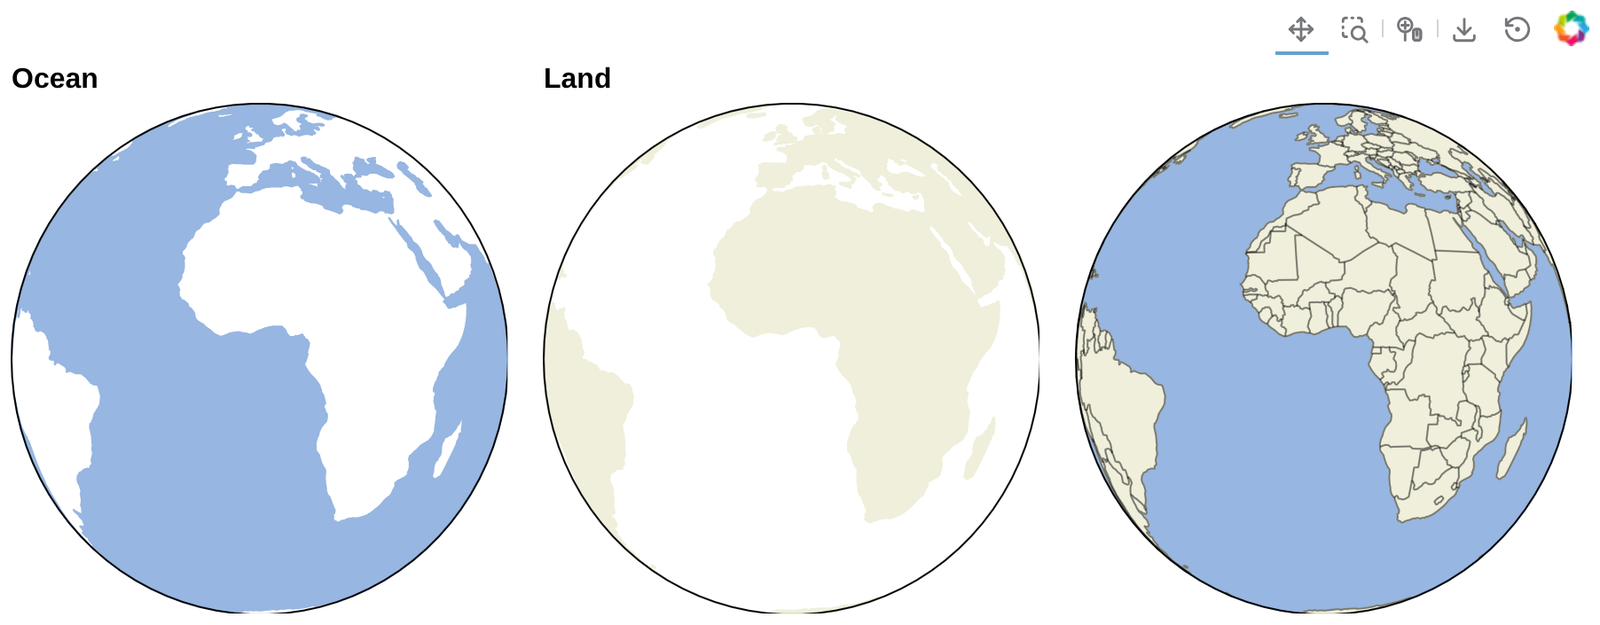

In [1]:
import geoviews as gv
import geoviews.feature as gf
import xarray as xr
from cartopy import crs

gv.extension('bokeh', 'matplotlib')

(gf.ocean + gf.land + gf.ocean * gf.land * gf.coastline * gf.borders).opts(
    'Feature', projection=crs.Geostationary(), global_extent=True, height=325)

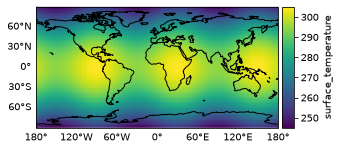

In [2]:
import numpy as np

# Build a small synthetic surface-temperature field (in kelvin) on a global grid
longitude = np.linspace(-180, 177.5, 144)
latitude = np.linspace(-90, 90, 73)
lon2d, lat2d = np.meshgrid(longitude, latitude)
surface_temperature = 250 + 50 * np.cos(np.deg2rad(lat2d)) + 5 * np.sin(np.deg2rad(3 * lon2d))

ds = xr.Dataset(
    {"surface_temperature": (("latitude", "longitude"), surface_temperature)},
    coords={"latitude": latitude, "longitude": longitude},
)

dataset = gv.Dataset(ds)
ensemble = dataset.to(gv.Image, ['longitude', 'latitude'], 'surface_temperature')

gv.output(ensemble.opts(cmap='viridis', colorbar=True, fig_size=120, backend='matplotlib') * gf.coastline(),
          backend='matplotlib')

## Example 2

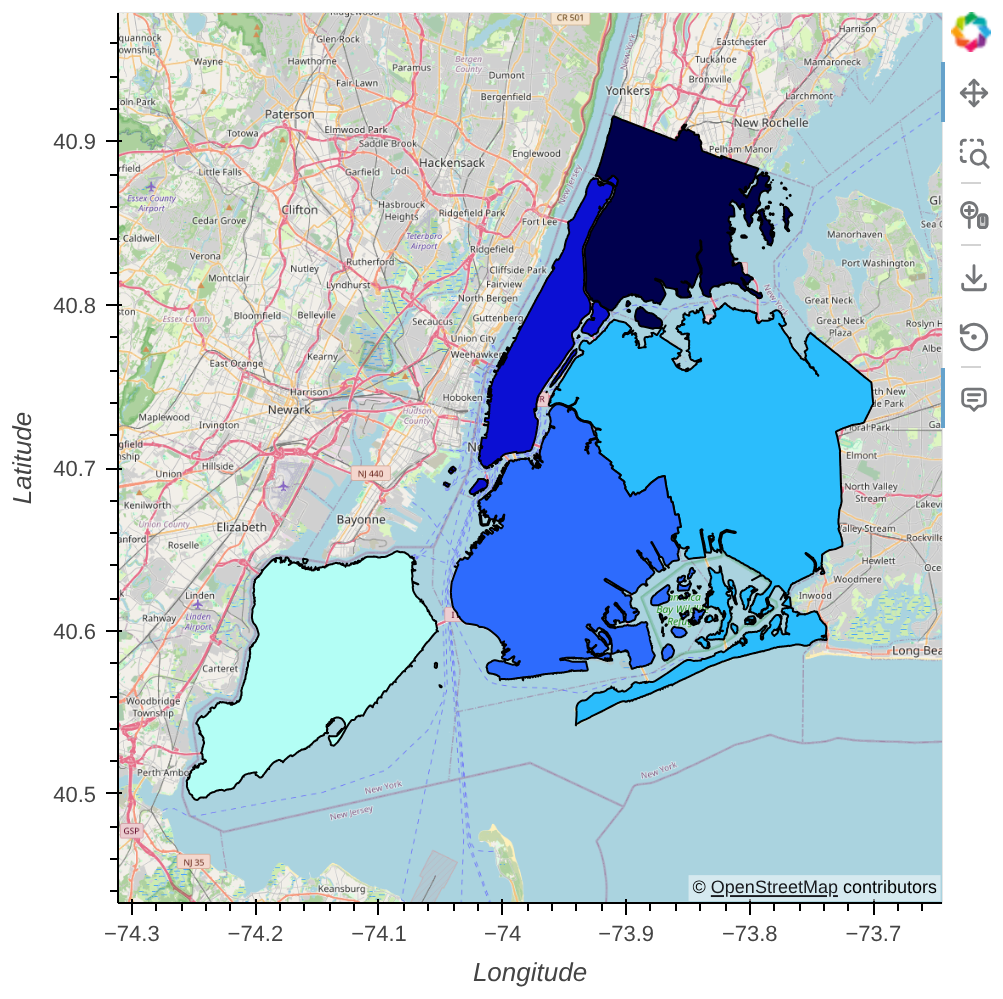

In [3]:
import geopandas as gpd
import geodatasets as gds

nybb = gpd.read_file(gds.get_path('nybb'))
poly_data = nybb.to_crs(crs.GOOGLE_MERCATOR.proj4_init)
gv.tile_sources.OSM * gv.Polygons(poly_data, vdims='BoroName', crs=crs.GOOGLE_MERCATOR).opts(height=500, width=500, tools=["hover"])

## Example 3

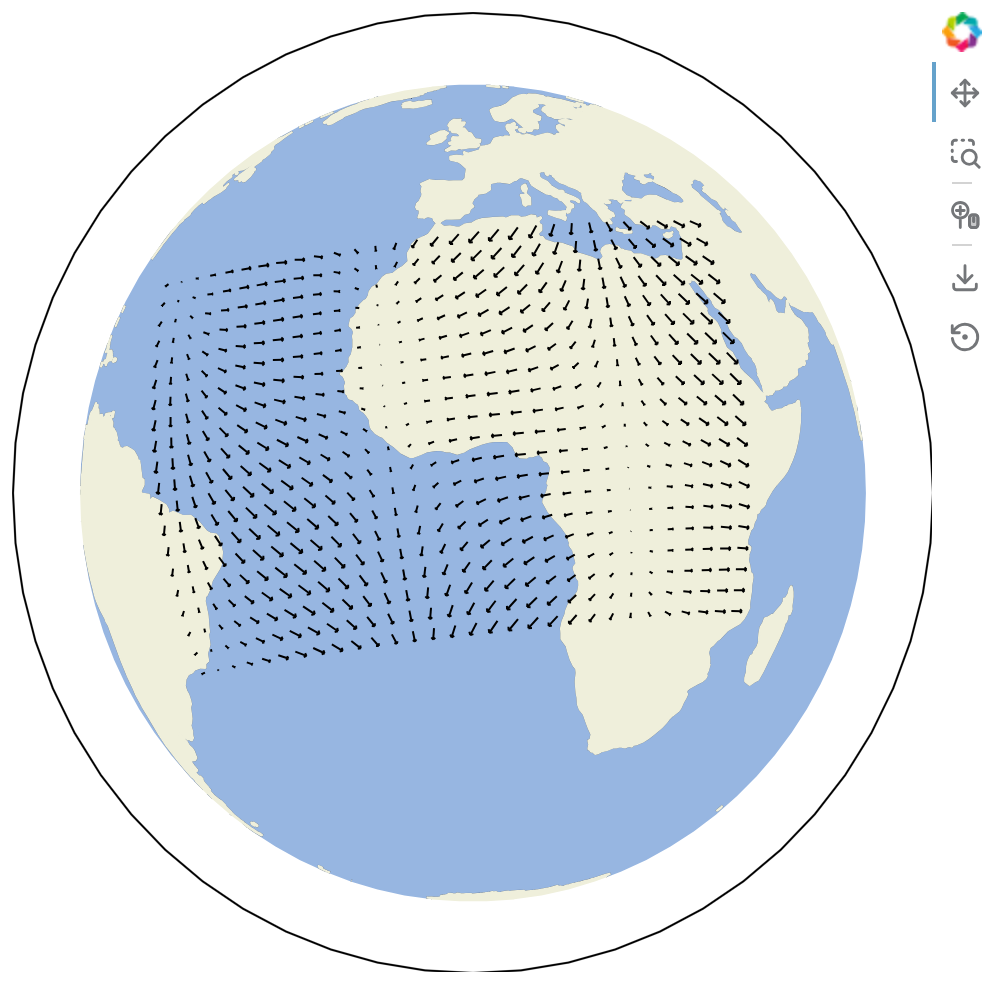

In [4]:
import numpy as np
import geoviews as gv
import geoviews.feature as gf
import cartopy.crs as ccrs

gv.extension('bokeh')

def sample_data(shape=(20, 30)):
    """
    Returns ``(x, y, u, v, crs)`` of some vector data
    computed mathematically. The returned crs will be a rotated
    pole CRS, meaning that the vectors will be unevenly spaced in
    regular PlateCarree space.

    """
    crs = ccrs.RotatedPole(pole_longitude=177.5, pole_latitude=37.5)

    x = np.linspace(311.9, 391.1, shape[1])
    y = np.linspace(-23.6, 24.8, shape[0])

    x2d, y2d = np.meshgrid(x, y)
    u = 10 * (2 * np.cos(2 * np.deg2rad(x2d) + 3 * np.deg2rad(y2d + 30)) ** 2)
    v = 20 * np.cos(6 * np.deg2rad(x2d))

    return x, y, u, v, crs

xs, ys, U, V, crs = sample_data()
mag = np.sqrt(U**2 + V**2)
angle = np.pi / 2 - np.arctan2(-V, -U)
vectorfield = gv.VectorField((xs, ys, angle, mag), crs=crs)

# Set the projection on the whole overlay so every layer is drawn in it
overlay = (gf.ocean * gf.coastline * gf.land * vectorfield.opts(magnitude='Magnitude')).opts(
    width=500, height=500, projection=ccrs.Orthographic(-10, 45), global_extent=True)

overlay